In [3]:
import os, re, glob, html, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

MAX_TRAIN = 60000     # SMOKE TEST first. Later: 60000 (or None = all ~145k)
MAX_VAL   = 10000
MAX_LEN   = 128       # tokens kept per review
MAX_VOCAB = 30000
MIN_FREQ  = 3

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print(device)

cuda


In [4]:
def find(name):
    p = glob.glob(f"/kaggle/input/**/{name}.*", recursive=True)
    assert p, f"{name} not found, check the Add Input step"
    return p[0]
def read(p): return pd.read_csv(p, sep="\t" if p.endswith(".tsv") else ",")

train_full = read(find("drugsComTrain_raw"))
test_df    = read(find("drugsComTest_raw"))

def tokenize(t):
    t = html.unescape(str(t)).lower()          # fixes things like &#039;
    t = re.sub(r"[^a-z0-9' ]+", " ", t)
    return t.split()
def to_label(r): return 0 if r <= 4 else (1 if r <= 6 else 2)

for d in (train_full, test_df):
    d.dropna(subset=["review", "rating"], inplace=True)
    d.reset_index(drop=True, inplace=True)
    d["tokens"] = d.review.map(tokenize)
    d["label"]  = d.rating.map(to_label)
    d["n_tok"]  = d.tokens.map(len)
print(len(train_full), len(test_df))

161297 53766


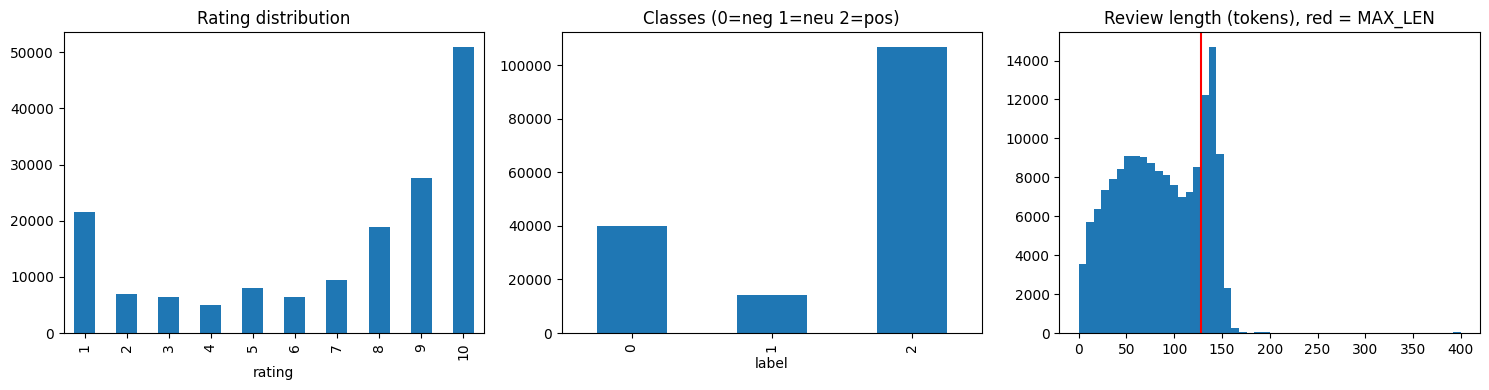

label
0    0.248455
1    0.089004
2    0.662542
Name: proportion, dtype: float64
count    161297.000000
mean         85.027384
std          45.261529
min           0.000000
25%          48.000000
50%          85.000000
75%         127.000000
max        1875.000000
Name: n_tok, dtype: float64
share of reviews longer than MAX_LEN: 0.23494547325740714


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
train_full.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="Rating distribution")
train_full.label.value_counts().sort_index().plot.bar(ax=ax[1], title="Classes (0=neg 1=neu 2=pos)")
ax[2].hist(train_full.n_tok.clip(upper=400), bins=50); ax[2].axvline(MAX_LEN, color="r")
ax[2].set_title("Review length (tokens), red = MAX_LEN")
plt.tight_layout(); plt.savefig("eda.png", dpi=150); plt.show()
print(train_full.label.value_counts(normalize=True).sort_index())
print(train_full.n_tok.describe())
print("share of reviews longer than MAX_LEN:", (train_full.n_tok > MAX_LEN).mean())

In [5]:
tr_all, va = train_test_split(train_full, test_size=0.1, stratify=train_full.label, random_state=42)
tr = train_test_split(tr_all, train_size=MAX_TRAIN, stratify=tr_all.label, random_state=42)[0] if MAX_TRAIN else tr_all
if MAX_VAL and len(va) > MAX_VAL:
    va = train_test_split(va, train_size=MAX_VAL, stratify=va.label, random_state=42)[0]

cnt  = Counter(t for toks in tr.tokens for t in toks)          # vocab from TRAIN only
itos = ["<pad>", "<unk>"] + [w for w, c in cnt.most_common(MAX_VOCAB) if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}

def make_tensors(df):
    n = len(df); X = torch.zeros(n, MAX_LEN, dtype=torch.long); L = torch.zeros(n, dtype=torch.long)
    for i, toks in enumerate(df.tokens):
        ids = [stoi.get(t, 1) for t in toks[:MAX_LEN]] or [1]
        X[i, :len(ids)] = torch.tensor(ids); L[i] = len(ids)
    return X, L, torch.tensor(df.label.values)

Xtr, Ltr, ytr = make_tensors(tr)
Xva, Lva, yva = make_tensors(va)
Xte, Lte, yte = make_tensors(test_df)
print(len(tr), len(va), len(test_df), "vocab:", len(itos))
print("train class share:", np.bincount(ytr.numpy()) / len(ytr))

def batches(X, L, y, bs, shuffle):
    idx = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), bs):
        j = idx[i:i+bs]; lb = L[j]; T = int(lb.max())           # trim padding to longest in batch
        yield X[j, :T].to(device), lb.to(device), y[j].to(device)

60000 10000 53766 vocab: 17208
train class share: [0.24846667 0.089      0.66253333]


In [6]:
class Cell(nn.Module):
    n_gates = 4
    def __init__(self, in_dim, H, h_dim):
        super().__init__()
        self.H, self.h_dim, self.c_dim, self.out_dim = H, h_dim, H, h_dim
        self.x2h = nn.Linear(in_dim, self.n_gates * H)               # W_x* and biases
        self.h2h = nn.Linear(h_dim, self.n_gates * H, bias=False)    # W_h*
        self.fslice = slice(H, 2 * H)                                # forget-gate bias slice

class VanillaLSTMCell(Cell):                                         # eq. 1-6
    def __init__(self, in_dim, H, P=None): super().__init__(in_dim, H, H)
    def forward(self, xw, h, c):
        i, f, g, o = (xw + self.h2h(h)).chunk(4, -1)
        i, f, o, g = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
        c = f * c + i * g
        return o * torch.tanh(c), c

class WMCCell(Cell):                                                 # eq. 7-12
    def __init__(self, in_dim, H, P=None):
        super().__init__(in_dim, H, H)
        self.c2if = nn.Linear(H, 2 * H, bias=False)                  # W_ci, W_cf on c_{t-1}
        self.c2o  = nn.Linear(H, H, bias=False)                      # W_co on c_t (NEW cell state)
    def forward(self, xw, h, c):
        i, f, g, o = (xw + self.h2h(h)).chunk(4, -1)
        ci, cf = torch.tanh(self.c2if(c)).chunk(2, -1)
        i, f, g = torch.sigmoid(i + ci), torch.sigmoid(f + cf), torch.tanh(g)
        c = f * c + i * g
        o = torch.sigmoid(o + torch.tanh(self.c2o(c)))               # output gate sees c_t
        return o * torch.tanh(c), c

class CIFGCell(Cell):                                                # eq. 13-18
    n_gates = 3
    def __init__(self, in_dim, H, P=None):
        super().__init__(in_dim, H, H); self.fslice = slice(0, H)
    def forward(self, xw, h, c):
        f, g, o = (xw + self.h2h(h)).chunk(3, -1)
        f, o, g = torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
        i = 1 - f                                                    # coupled input gate
        c = f * c + i * g
        return o * torch.tanh(c), c

class LSTMPCell(Cell):                                               # eq. 19-25
    def __init__(self, in_dim, H, P):
        super().__init__(in_dim, H, P)                               # h has size P, c has size H
        self.proj = nn.Linear(H, P)                                  # W_p, b_p
    def forward(self, xw, h, c):
        i, f, g, o = (xw + self.h2h(h)).chunk(4, -1)
        i, f, o, g = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
        c = f * c + i * g
        m = o * torch.tanh(c)
        return self.proj(m), c

CELLS = {"lstm": VanillaLSTMCell, "wmc": WMCCell, "cifg": CIFGCell, "lstmp": LSTMPCell}

In [8]:
class Encoder(nn.Module):
    def __init__(self, cell_name, in_dim, H, P, layers, dropout):
        super().__init__(); cells, d = [], in_dim
        for _ in range(layers):
            c = CELLS[cell_name](d, H, P); cells.append(c); d = c.out_dim
        self.cells = nn.ModuleList(cells); self.drop = nn.Dropout(dropout); self.out_dim = d
    def forward(self, x, lengths):
        B, T, _ = x.shape
        mask = (torch.arange(T, device=x.device)[None, :] < lengths[:, None]).float().unsqueeze(-1)
        inp = x
        for k, cell in enumerate(self.cells):
            xw = cell.x2h(inp)                                       # input projection for ALL steps at once
            h = x.new_zeros(B, cell.h_dim); c = x.new_zeros(B, cell.c_dim); outs = []
            for t in range(T):
                h_new, c_new = cell(xw[:, t], h, c); m = mask[:, t]
                h = m * h_new + (1 - m) * h; c = m * c_new + (1 - m) * c
                outs.append(h)
            inp = torch.stack(outs, 1)
            if k < len(self.cells) - 1: inp = self.drop(inp)
        return h

class Classifier(nn.Module):
    def __init__(self, vocab, cell_name, E, H, P, layers, dropout, n_cls=3):
        super().__init__()
        self.emb = nn.Embedding(vocab, E, padding_idx=0); self.drop = nn.Dropout(dropout)
        self.enc = Encoder(cell_name, E, H, P, layers, dropout)
        self.fc  = nn.Linear(self.enc.out_dim, n_cls)
    def forward(self, x, lengths):
        return self.fc(self.drop(self.enc(self.drop(self.emb(x)), lengths)))

def init_cells(model, scheme, forget_bias):
    for cell in model.enc.cells:
        for m in cell.modules():
            if isinstance(m, nn.Linear):
                if scheme == "xavier": nn.init.xavier_uniform_(m.weight)
                elif scheme == "orthogonal": nn.init.orthogonal_(m.weight)
        if forget_bias:
            with torch.no_grad(): cell.x2h.bias[cell.fslice].fill_(1.0)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

for n in CELLS:
    m = Classifier(len(itos), n, 128, 128, 64, 1, 0.3)
    print(f"{n:6s} total={count_params(m):,}  recurrent={sum(p.numel() for p in m.enc.parameters()):,}")

lstm   total=2,334,595  recurrent=131,584
wmc    total=2,383,747  recurrent=180,736
cifg   total=2,301,699  recurrent=98,688
lstmp  total=2,309,891  recurrent=107,072


In [9]:
torch.manual_seed(0); B, T, D, H = 4, 7, 10, 16
mine = VanillaLSTMCell(D, H).double(); ref = nn.LSTM(D, H, batch_first=True).double()
with torch.no_grad():
    ref.weight_ih_l0.copy_(mine.x2h.weight); ref.bias_ih_l0.copy_(mine.x2h.bias)
    ref.weight_hh_l0.copy_(mine.h2h.weight); ref.bias_hh_l0.zero_()
x = torch.randn(B, T, D).double(); ref_out, _ = ref(x)
xw = mine.x2h(x); h = torch.zeros(B, H).double(); c = torch.zeros(B, H).double(); outs = []
for t in range(T):
    h, c = mine(xw[:, t], h, c); outs.append(h)
print("max abs diff vs nn.LSTM:", (torch.stack(outs, 1) - ref_out).abs().max().item())

max abs diff vs nn.LSTM: 0.0


In [11]:
def evaluate(model, X, L, y, bs=512):
    model.eval(); preds, loss_sum = [], 0.0
    with torch.no_grad():
        for xb, lb, yb in batches(X, L, y, bs, False):
            out = model(xb, lb); loss_sum += F.cross_entropy(out, yb, reduction="sum").item()
            preds.append(out.argmax(1).cpu())
    p = torch.cat(preds).numpy(); t = y.numpy()
    return dict(loss=loss_sum / len(y), acc=accuracy_score(t, p), f1=f1_score(t, p, average="macro")), p

DEFAULT = dict(cell="lstm", E=128, H=128, P=64, layers=1, dropout=0.3, lr=1e-3, opt="adam", bs=128,
               init="default", forget_bias=True, epochs=8, patience=3, wd=0.0, clip=1.0,
               class_weight=False, seed=0)

def make_opt(name, params, lr, wd):
    if name == "adam":    return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if name == "adamw":   return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=wd)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)

def run(do_test=True, verbose=True, **kw):
    cfg = {**DEFAULT, **kw}; set_seed(cfg["seed"])
    model = Classifier(len(itos), cfg["cell"], cfg["E"], cfg["H"], cfg["P"], cfg["layers"], cfg["dropout"]).to(device)
    init_cells(model, cfg["init"], cfg["forget_bias"])
    opt = make_opt(cfg["opt"], model.parameters(), cfg["lr"], cfg["wd"])
    w = None
    if cfg["class_weight"]:
        cn = np.bincount(ytr.numpy(), minlength=3)
        w = torch.tensor(len(ytr) / (3 * cn), dtype=torch.float, device=device)
    best, best_state, bad, hist, times = -1, None, 0, [], []
    for ep in range(cfg["epochs"]):
        model.train(); t0 = time.time(); tot = n = 0
        for xb, lb, yb in batches(Xtr, Ltr, ytr, cfg["bs"], True):
            opt.zero_grad(); loss = F.cross_entropy(model(xb, lb), yb, weight=w); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"]); opt.step()
            tot += loss.item() * len(yb); n += len(yb)
        times.append(time.time() - t0)
        v, _ = evaluate(model, Xva, Lva, yva)
        hist.append(dict(epoch=ep + 1, train_loss=tot / n, val_loss=v["loss"], val_acc=v["acc"], val_f1=v["f1"]))
        if verbose:
            print(f"{cfg['cell']:5s} ep{ep+1} train {tot/n:.3f} | val loss {v['loss']:.3f} acc {v['acc']:.3f} f1 {v['f1']:.3f} | {times[-1]:.0f}s")
        if v["f1"] > best:
            best = v["f1"]; bad = 0
            best_state = {k: x.detach().clone() for k, x in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["patience"]: break
    model.load_state_dict(best_state)
    res = dict(cfg, params=count_params(model), best_val_f1=best, epochs_run=len(hist), sec_per_epoch=float(np.mean(times)))
    pred = None
    if do_test:
        t, pred = evaluate(model, Xte, Lte, yte); res.update(test_acc=t["acc"], test_f1=t["f1"])
    return res, hist, model, pred

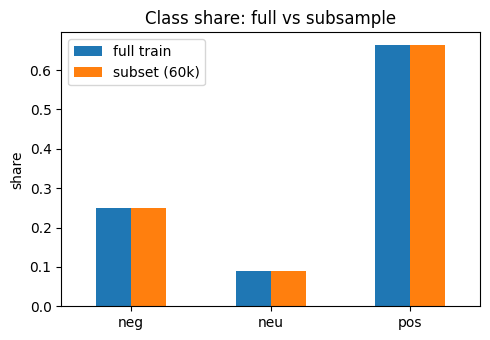

     full train  subset (60k)
neg       0.248         0.248
neu       0.089         0.089
pos       0.663         0.663


In [12]:
shares = pd.DataFrame({
    "full train": train_full.label.value_counts(normalize=True).sort_index(),
    "subset (60k)": pd.Series(np.bincount(ytr.numpy()) / len(ytr)),
})
shares.index = ["neg", "neu", "pos"]
shares.plot.bar(figsize=(5, 3.5), rot=0, title="Class share: full vs subsample")
plt.ylabel("share"); plt.tight_layout(); plt.savefig("subset_check.png", dpi=150); plt.show()
print(shares.round(3))

In [13]:
for c in ["lstm", "wmc", "cifg", "lstmp"]:
    r, h, _, _ = run(cell=c, epochs=2, do_test=False)

lstm  ep1 train 0.757 | val loss 0.741 acc 0.737 f1 0.447 | 61s
lstm  ep2 train 0.634 | val loss 0.660 acc 0.769 f1 0.494 | 60s
wmc   ep1 train 0.740 | val loss 0.641 acc 0.757 f1 0.481 | 74s
wmc   ep2 train 0.609 | val loss 0.573 acc 0.786 f1 0.515 | 73s
cifg  ep1 train 0.741 | val loss 0.636 acc 0.767 f1 0.499 | 52s
cifg  ep2 train 0.610 | val loss 0.596 acc 0.775 f1 0.518 | 52s
lstmp ep1 train 0.763 | val loss 0.664 acc 0.751 f1 0.487 | 65s
lstmp ep2 train 0.640 | val loss 0.663 acc 0.768 f1 0.504 | 64s


lstm 0 0.5783 0.5801
lstm 1 0.5857 0.5853
lstm 2 0.5783 0.5804
wmc 0 0.6084 0.6095
wmc 1 0.5861 0.5877
wmc 2 0.5863 0.592
cifg 0 0.584 0.5836
cifg 1 0.5934 0.5937
cifg 2 0.5961 0.5992
lstmp 0 0.5853 0.5859
lstmp 1 0.5894 0.596
lstmp 2 0.5746 0.5757
        params  val_f1  val_f1_std  test_acc  test_f1  test_f1_std  \
cell                                                                 
cifg   2301699  0.5912      0.0063    0.8145   0.5922       0.0079   
lstm   2334595  0.5808      0.0042    0.8092   0.5820       0.0029   
lstmp  2309891  0.5831      0.0076    0.8115   0.5859       0.0101   
wmc    2383747  0.5936      0.0128    0.8150   0.5964       0.0115   

       sec_per_epoch  
cell                  
cifg         53.4837  
lstm         62.0868  
lstmp        66.8241  
wmc          76.0862  


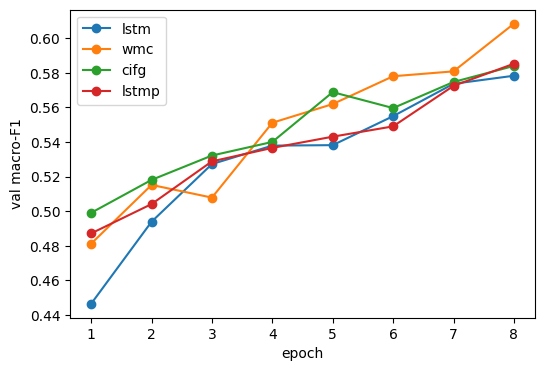

In [30]:
RESULTS, HIST, MODELS = [], {}, {}
for cell in ["lstm", "wmc", "cifg", "lstmp"]:
    for seed in [0, 1, 2]:
        r, h, m, _ = run(cell=cell, seed=seed, epochs=8, verbose=False)   # was: r, h, _, _
        if seed == 0: MODELS[cell] = m                                   # new line
        r["exp"] = "A_main"; RESULTS.append(r); HIST[("A", cell, seed)] = h
        print(cell, seed, round(r["best_val_f1"], 4), round(r["test_f1"], 4))
        pd.DataFrame(RESULTS).to_csv("results.csv", index=False)

dfA = pd.DataFrame(RESULTS)
summary = dfA[dfA.exp == "A_main"].groupby("cell").agg(
    params=("params", "first"), val_f1=("best_val_f1", "mean"), val_f1_std=("best_val_f1", "std"),
    test_acc=("test_acc", "mean"), test_f1=("test_f1", "mean"), test_f1_std=("test_f1", "std"),
    sec_per_epoch=("sec_per_epoch", "mean")).round(4)
print(summary); summary.to_csv("summary_A.csv")

plt.figure(figsize=(6, 4))
for cell in CELLS:
    h = pd.DataFrame(HIST[("A", cell, 0)]); plt.plot(h.epoch, h.val_f1, marker="o", label=cell)
plt.xlabel("epoch"); plt.ylabel("val macro-F1"); plt.legend(); plt.savefig("curves_A.png", dpi=150); plt.show()

In [31]:
import shutil
shutil.copy("results.csv",   "results_A_60k.csv")
shutil.copy("summary_A.csv", "summary_A_60k.csv")
shutil.copy("curves_A.png",  "curves_A_60k.png")

from IPython.display import FileLink, display
for f in ["results_A_60k.csv", "summary_A_60k.csv", "curves_A_60k.png"]:
    display(FileLink(f))

/kaggle/working/results_A_60k.csv

/kaggle/working/summary_A_60k.csv

/kaggle/working/curves_A_60k.png

In [33]:
print(pd.read_csv("results_A_60k.csv").shape)        # expect (12, ...)
print(pd.read_csv("summary_A_60k.csv", index_col=0)[["params", "test_f1"]])
print("memory ok:", "dfA" in globals(), "HIST" in globals(), len(HIST))   # expect True True 12

(12, 24)
        params  test_f1
cell                   
cifg   2301699   0.5922
lstm   2334595   0.5820
lstmp  2309891   0.5859
wmc    2383747   0.5964
memory ok: True True 12


In [17]:
from IPython.display import FileLink, display
for f in ["results.csv", "summary_A.csv", "results_pilot_3k.csv", "summary_pilot_3k.csv", "eda.png", "curves_A.png"]:
    display(FileLink(f))

/kaggle/working/results.csv

/kaggle/working/summary_A.csv

/kaggle/working/results_pilot_3k.csv

/kaggle/working/summary_pilot_3k.csv

/kaggle/working/eda.png

/kaggle/working/curves_A.png

In [32]:
import os
print(sorted(os.listdir("/kaggle/working")))

['.virtual_documents', 'curves_A.png', 'curves_A_60k.png', 'eda.png', 'results.csv', 'results_A_60k.csv', 'results_pilot_3k.csv', 'subset_check.png', 'summary_A.csv', 'summary_A_60k.csv', 'summary_pilot_3k.csv']


wmc H = 106 | recurrent params 133348 | target 131584
wmc 0 0.5749 0.581
wmc 1 0.5994 0.6022
wmc 2 0.58 0.5894
cifg H = 154 | recurrent params 130746 | target 131584
cifg 0 0.5905 0.5842
cifg 1 0.6119 0.6161
cifg 2 0.5897 0.5947
lstmp H = 148 | recurrent params 131202 | target 131584
lstmp 0 0.589 0.5857
lstmp 1 0.5819 0.5917
lstmp 2 0.5959 0.611
         H   params  val_f1  val_f1_std  test_acc  test_f1  test_f1_std  \
cell                                                                      
cifg   154  2333835  0.5974      0.0126    0.8145   0.5983       0.0163   
lstm   128  2334595  0.5808      0.0042    0.8092   0.5820       0.0029   
lstmp  148  2334051  0.5890      0.0070    0.8115   0.5961       0.0132   
wmc    106  2336293  0.5848      0.0129    0.8115   0.5909       0.0106   

       sec_per_epoch  
cell                  
cifg         58.5346  
lstm         62.0868  
lstmp        72.5023  
wmc          70.0357  


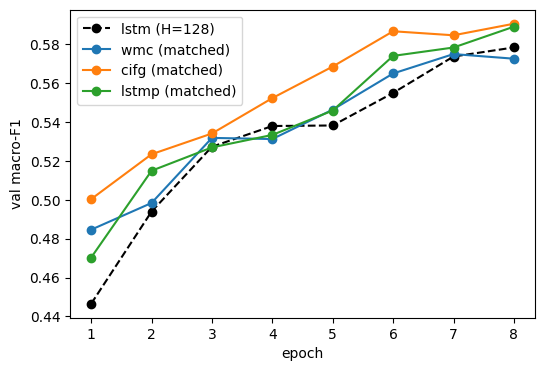

/kaggle/working/results_B.csv

/kaggle/working/summary_B.csv

/kaggle/working/curves_B.png

In [34]:
def rec_params(cell, H):
    m = Classifier(len(itos), cell, 128, H, H // 2, 1, 0.3)
    return sum(p.numel() for p in m.enc.parameters())

target = rec_params("lstm", 128)
RES_B = []
for cell in ["wmc", "cifg", "lstmp"]:
    Hm = min(range(32, 513, 2), key=lambda H: abs(rec_params(cell, H) - target))
    print(cell, "H =", Hm, "| recurrent params", rec_params(cell, Hm), "| target", target)
    for seed in [0, 1, 2]:
        r, h, _, _ = run(cell=cell, H=Hm, P=Hm // 2, seed=seed, epochs=8, verbose=False)
        r["exp"] = "B_matched"; RES_B.append(r); RESULTS.append(r); HIST[("B", cell, seed)] = h
        print(cell, seed, round(r["best_val_f1"], 4), round(r["test_f1"], 4))
        pd.DataFrame(RES_B).to_csv("results_B.csv", index=False)

dfB = pd.DataFrame(RES_B)
both = pd.concat([dfB, dfA[dfA.cell == "lstm"]])          # vanilla (H=128) comes from Experiment A
summary_B = both.groupby("cell").agg(
    H=("H", "first"), params=("params", "first"),
    val_f1=("best_val_f1", "mean"), val_f1_std=("best_val_f1", "std"),
    test_acc=("test_acc", "mean"), test_f1=("test_f1", "mean"), test_f1_std=("test_f1", "std"),
    sec_per_epoch=("sec_per_epoch", "mean")).round(4)
print(summary_B); summary_B.to_csv("summary_B.csv")

plt.figure(figsize=(6, 4))
h0 = pd.DataFrame(HIST[("A", "lstm", 0)]); plt.plot(h0.epoch, h0.val_f1, "k--", marker="o", label="lstm (H=128)")
for cell in ["wmc", "cifg", "lstmp"]:
    h = pd.DataFrame(HIST[("B", cell, 0)]); plt.plot(h.epoch, h.val_f1, marker="o", label=f"{cell} (matched)")
plt.xlabel("epoch"); plt.ylabel("val macro-F1"); plt.legend(); plt.savefig("curves_B.png", dpi=150); plt.show()

from IPython.display import FileLink, display
for f in ["results_B.csv", "summary_B.csv", "curves_B.png"]: display(FileLink(f))

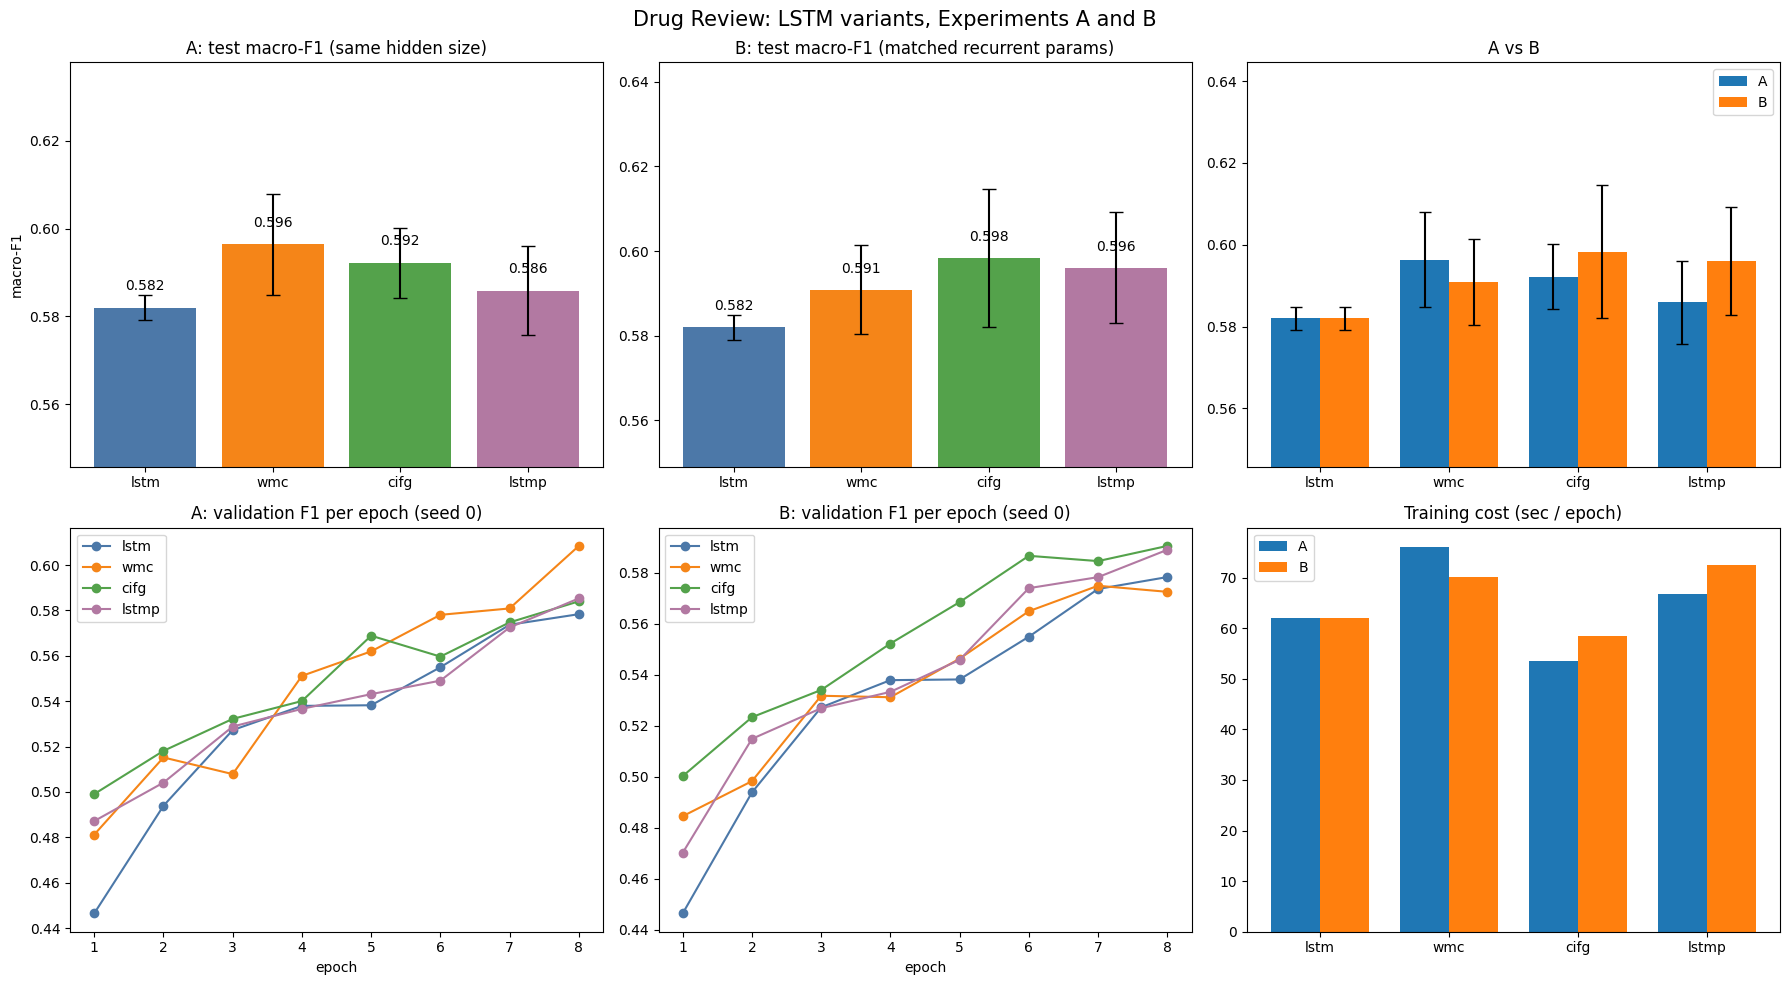

             A                                 B                            \
        params test_acc test_f1 test_f1_std    H   params test_acc test_f1   
cell                                                                         
lstm   2334595   0.8092  0.5820      0.0029  128  2334595   0.8092  0.5820   
wmc    2383747   0.8150  0.5964      0.0115  106  2336293   0.8115  0.5909   
cifg   2301699   0.8145  0.5922      0.0079  154  2333835   0.8145  0.5983   
lstmp  2309891   0.8115  0.5859      0.0101  148  2334051   0.8115  0.5961   

                   
      test_f1_std  
cell               
lstm       0.0029  
wmc        0.0106  
cifg       0.0163  
lstmp      0.0132  
       test_f1 3k  test_f1 60k
cell                          
cifg       0.4440       0.5922
lstm       0.4261       0.5820
lstmp      0.4260       0.5859
wmc        0.4440       0.5964


/kaggle/working/dashboard_A_B.png

/kaggle/working/comparison_A_B.csv

In [35]:
from IPython.display import FileLink, display
order = ["lstm", "wmc", "cifg", "lstmp"]
sA, sB = summary.loc[order], summary_B.loc[order]
colors = ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]

def zoom(ax, vals, errs):
    lo, hi = min(vals - errs), max(vals + errs)
    ax.set_ylim(lo - 0.03, hi + 0.03)      # axis is zoomed on purpose; say so in the report

fig, ax = plt.subplots(2, 3, figsize=(18, 10))

# 1) A: test F1 with error bars
ax[0,0].bar(order, sA.test_f1, yerr=sA.test_f1_std, capsize=5, color=colors)
zoom(ax[0,0], sA.test_f1.values, sA.test_f1_std.values)
for i, v in enumerate(sA.test_f1): ax[0,0].text(i, v + 0.004, f"{v:.3f}", ha="center")
ax[0,0].set_title("A: test macro-F1 (same hidden size)"); ax[0,0].set_ylabel("macro-F1")

# 2) B: test F1 with error bars
ax[0,1].bar(order, sB.test_f1, yerr=sB.test_f1_std, capsize=5, color=colors)
zoom(ax[0,1], sB.test_f1.values, sB.test_f1_std.values)
for i, v in enumerate(sB.test_f1): ax[0,1].text(i, v + 0.004, f"{v:.3f}", ha="center")
ax[0,1].set_title("B: test macro-F1 (matched recurrent params)")

# 3) A vs B side by side (vanilla is the same run in both)
x = np.arange(len(order)); w = 0.38
ax[0,2].bar(x - w/2, sA.test_f1, w, yerr=sA.test_f1_std, capsize=4, label="A")
ax[0,2].bar(x + w/2, sB.test_f1, w, yerr=sB.test_f1_std, capsize=4, label="B")
ax[0,2].set_xticks(x); ax[0,2].set_xticklabels(order); ax[0,2].legend()
zoom(ax[0,2], np.r_[sA.test_f1.values, sB.test_f1.values], np.r_[sA.test_f1_std.values, sB.test_f1_std.values])
ax[0,2].set_title("A vs B")

# 4) A curves (seed 0)
for c, col in zip(order, colors):
    h = pd.DataFrame(HIST[("A", c, 0)]); ax[1,0].plot(h.epoch, h.val_f1, marker="o", color=col, label=c)
ax[1,0].set_title("A: validation F1 per epoch (seed 0)"); ax[1,0].set_xlabel("epoch"); ax[1,0].legend()

# 5) B curves (seed 0); vanilla comes from A
for c, col in zip(order, colors):
    key = ("A", c, 0) if c == "lstm" else ("B", c, 0)
    h = pd.DataFrame(HIST[key]); ax[1,1].plot(h.epoch, h.val_f1, marker="o", color=col, label=c)
ax[1,1].set_title("B: validation F1 per epoch (seed 0)"); ax[1,1].set_xlabel("epoch"); ax[1,1].legend()

# 6) cost: seconds per epoch, A vs B
ax[1,2].bar(x - w/2, sA.sec_per_epoch, w, label="A"); ax[1,2].bar(x + w/2, sB.sec_per_epoch, w, label="B")
ax[1,2].set_xticks(x); ax[1,2].set_xticklabels(order); ax[1,2].legend()
ax[1,2].set_title("Training cost (sec / epoch)")

plt.suptitle("Drug Review: LSTM variants, Experiments A and B", fontsize=15)
plt.tight_layout(); plt.savefig("dashboard_A_B.png", dpi=170); plt.show()

# combined table
comp = pd.concat({"A": sA[["params", "test_acc", "test_f1", "test_f1_std"]],
                  "B": sB[["H", "params", "test_acc", "test_f1", "test_f1_std"]]}, axis=1)
print(comp.round(4)); comp.to_csv("comparison_A_B.csv")

# effect of data size: 3k pilot vs 60k
pil = pd.read_csv("summary_pilot_3k.csv", index_col=0)
print(pd.DataFrame({"test_f1 3k": pil.test_f1, "test_f1 60k": summary.test_f1}).round(4))

for f in ["dashboard_A_B.png", "comparison_A_B.csv"]: display(FileLink(f))

In [36]:
a = pd.read_csv("results_A_60k.csv"); b = pd.read_csv("results_B.csv")
cols = ["cell", "seed", "H", "test_acc", "test_f1"]
print(a[a.cell.isin(["cifg", "lstmp"])][cols].round(4))
print(b[b.cell.isin(["cifg", "lstmp"])][cols].round(4))

     cell  seed    H  test_acc  test_f1
6    cifg     0  128    0.8141   0.5836
7    cifg     1  128    0.8137   0.5937
8    cifg     2  128    0.8156   0.5992
9   lstmp     0  128    0.8120   0.5859
10  lstmp     1  128    0.8121   0.5960
11  lstmp     2  128    0.8103   0.5757
    cell  seed    H  test_acc  test_f1
3   cifg     0  154    0.8140   0.5842
4   cifg     1  154    0.8164   0.6161
5   cifg     2  154    0.8131   0.5947
6  lstmp     0  148    0.8070   0.5857
7  lstmp     1  148    0.8134   0.5917
8  lstmp     2  148    0.8143   0.6110


In [1]:
BEST = "cifg"; print("tuning: lstm and", BEST)
trials = ([dict()] +                                             # baseline, run once
          [dict(lr=v) for v in [3e-4, 3e-3]] +
          [dict(opt="adamw", wd=0.01), dict(opt="rmsprop"), dict(opt="sgd", lr=0.1)] +
          [dict(bs=v) for v in [64, 256]] +
          [dict(init=v) for v in ["xavier", "orthogonal"]] +
          [dict(dropout=v) for v in [0.1, 0.5]] +
          [dict(class_weight=True)])
rows = []
for cell in ["lstm", BEST]:
    for t in trials:
        r, h, _, _ = run(cell=cell, epochs=5, do_test=False, verbose=False, **t)
        r["exp"] = "C_hparam"; r["trial"] = str(t) if t else "baseline"; rows.append(r)
        print(cell, t or "baseline", round(r["best_val_f1"], 4))
        pd.DataFrame(rows).to_csv("hparam.csv", index=False)     # saved after every run
dfC = pd.DataFrame(rows)
tab = dfC.pivot_table(index="trial", columns="cell", values="best_val_f1").round(4)
print(tab); tab.to_csv("hparam_table.csv")
from IPython.display import FileLink, display
for f in ["hparam.csv", "hparam_table.csv"]: display(FileLink(f))

tuning: lstm and cifg


NameError: name 'run' is not defined

                   lstm    cifg  lstm_delta  cifg_delta
baseline         0.5382  0.5689      0.0000      0.0000
lr=3e-4          0.4980  0.5090     -0.0402     -0.0599
lr=3e-3          0.5647  0.5986      0.0265      0.0297
adamw wd=0.01    0.5379  0.5722     -0.0003      0.0033
rmsprop          0.5475  0.5612      0.0093     -0.0077
sgd lr=0.1       0.5017  0.5165     -0.0365     -0.0524
bs=64            0.5622  0.6028      0.0240      0.0339
bs=256           0.5287  0.5287     -0.0095     -0.0402
init xavier      0.5378  0.5592     -0.0004     -0.0097
init orthogonal  0.5487  0.5550      0.0105     -0.0139
dropout=0.1      0.5907  0.5934      0.0525      0.0245
dropout=0.5      0.5078  0.5292     -0.0304     -0.0397
class_weight     0.5961  0.5879      0.0579      0.0190


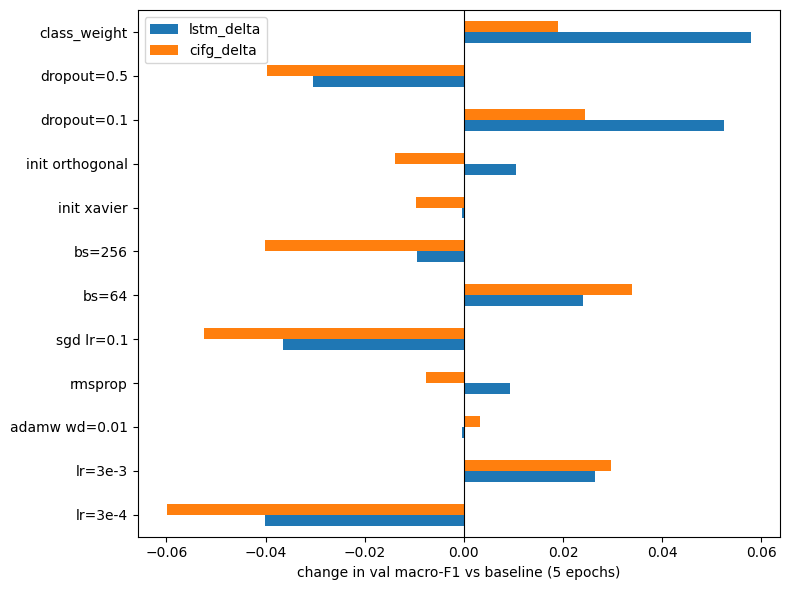

/kaggle/working/hparam_table_rebuilt.csv

/kaggle/working/hparam_plot.png

In [14]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import FileLink, display

rows = {   # trial: (lstm, cifg) = validation macro-F1 after 5 epochs, single run each
 "baseline":        (0.5382, 0.5689),
 "lr=3e-4":         (0.4980, 0.5090),
 "lr=3e-3":         (0.5647, 0.5986),
 "adamw wd=0.01":   (0.5379, 0.5722),
 "rmsprop":         (0.5475, 0.5612),
 "sgd lr=0.1":      (0.5017, 0.5165),
 "bs=64":           (0.5622, 0.6028),
 "bs=256":          (0.5287, 0.5287),
 "init xavier":     (0.5378, 0.5592),
 "init orthogonal": (0.5487, 0.5550),
 "dropout=0.1":     (0.5907, 0.5934),
 "dropout=0.5":     (0.5078, 0.5292),
 "class_weight":    (0.5961, 0.5879),
}
tab = pd.DataFrame(rows, index=["lstm", "cifg"]).T
tab["lstm_delta"] = tab.lstm - tab.loc["baseline", "lstm"]
tab["cifg_delta"] = tab.cifg - tab.loc["baseline", "cifg"]
print(tab.round(4)); tab.round(4).to_csv("hparam_table_rebuilt.csv")

d = tab.drop("baseline")[["lstm_delta", "cifg_delta"]]
d.plot.barh(figsize=(8, 6)); plt.axvline(0, color="k", lw=0.8)
plt.xlabel("change in val macro-F1 vs baseline (5 epochs)"); plt.tight_layout()
plt.savefig("hparam_plot.png", dpi=170); plt.show()
for f in ["hparam_table_rebuilt.csv", "hparam_plot.png"]: display(FileLink(f))

cifg  ep1 train 0.714 | val loss 0.618 acc 0.777 f1 0.509 | 92s
cifg  ep2 train 0.585 | val loss 0.556 acc 0.791 f1 0.528 | 92s
cifg  ep3 train 0.532 | val loss 0.537 acc 0.805 f1 0.544 | 93s
cifg  ep4 train 0.492 | val loss 0.515 acc 0.807 f1 0.553 | 92s
cifg  ep5 train 0.460 | val loss 0.498 acc 0.813 f1 0.603 | 92s
cifg  ep6 train 0.434 | val loss 0.507 acc 0.814 f1 0.591 | 92s
cifg  ep7 train 0.411 | val loss 0.528 acc 0.816 f1 0.585 | 92s
cifg  ep8 train 0.389 | val loss 0.517 acc 0.816 f1 0.599 | 92s
cifg  ep9 train 0.371 | val loss 0.508 acc 0.815 f1 0.624 | 92s
cifg  ep10 train 0.354 | val loss 0.507 acc 0.816 f1 0.640 | 92s
cifg  ep11 train 0.338 | val loss 0.512 acc 0.820 f1 0.625 | 92s
cifg  ep12 train 0.323 | val loss 0.558 acc 0.822 f1 0.645 | 92s
{'cell': 'cifg', 'params': 2301699, 'epochs_run': 12, 'best_val_f1': 0.6453560899758218, 'test_acc': 0.8190678123721311, 'test_f1': 0.6399440548731031}
              precision    recall  f1-score   support

         neg      0.78

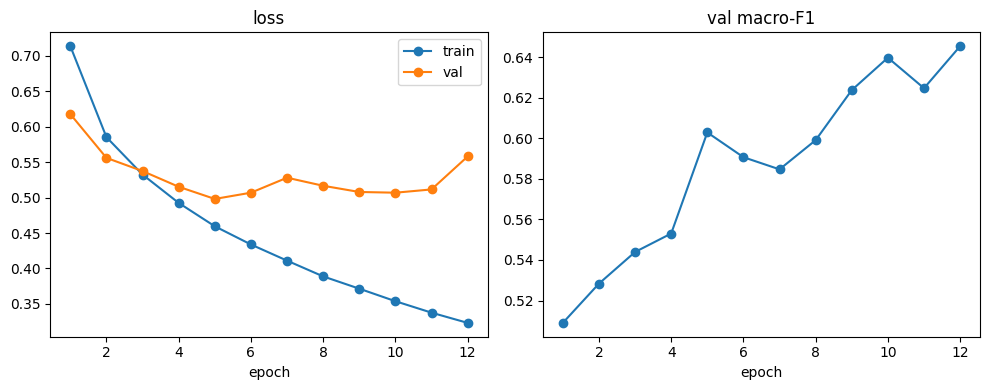

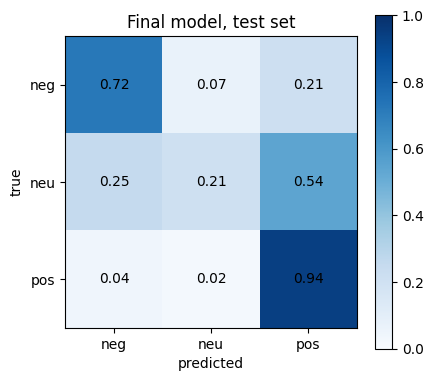

      bucket      n     acc  macro_f1
0     (0,30]   7387  0.8357    0.6268
1    (30,60]  10660  0.8197    0.6375
2   (60,100]  14030  0.8160    0.6400
3  (100,128]  21689  0.8151    0.6394


/kaggle/working/final_result.csv

/kaggle/working/final_history.csv

/kaggle/working/final_class_report.csv

/kaggle/working/final_by_length.csv

/kaggle/working/final_curves.png

/kaggle/working/confusion.png

/kaggle/working/final_cifg.pt

In [15]:
final_kw = dict(cell="cifg", bs=64, epochs=12, patience=4, seed=0)
res, hist, model, pred = run(**final_kw)                     # prints each epoch
print({k: res[k] for k in ["cell", "params", "epochs_run", "best_val_f1", "test_acc", "test_f1"]})

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
pd.DataFrame([res]).to_csv("final_result.csv", index=False)
pd.DataFrame(hist).to_csv("final_history.csv", index=False)
torch.save(model.state_dict(), "final_cifg.pt")

names = ["neg", "neu", "pos"]; yt = yte.numpy()
print(classification_report(yt, pred, target_names=names, digits=3))
pd.DataFrame(classification_report(yt, pred, target_names=names, output_dict=True)).T.round(4).to_csv("final_class_report.csv")

# training curves
hh = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(hh.epoch, hh.train_loss, marker="o", label="train"); ax[0].plot(hh.epoch, hh.val_loss, marker="o", label="val")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hh.epoch, hh.val_f1, marker="o"); ax[1].set_title("val macro-F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("final_curves.png", dpi=150); plt.show()

# confusion matrix (row-normalized)
cm = confusion_matrix(yt, pred, normalize="true")
plt.figure(figsize=(4.5, 4)); plt.imshow(cm, cmap="Blues", vmin=0, vmax=1); plt.colorbar()
plt.xticks(range(3), names); plt.yticks(range(3), names)
for i in range(3):
    for j in range(3): plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Final model, test set")
plt.tight_layout(); plt.savefig("confusion.png", dpi=150); plt.show()

# accuracy by review length (lengths are truncated at MAX_LEN)
lens = Lte.numpy(); out = []
for a, b in [(0, 30), (30, 60), (60, 100), (100, MAX_LEN)]:
    m_ = (lens > a) & (lens <= b)
    out.append(dict(bucket=f"({a},{b}]", n=int(m_.sum()),
                    acc=accuracy_score(yt[m_], pred[m_]), macro_f1=f1_score(yt[m_], pred[m_], average="macro")))
bylen = pd.DataFrame(out).round(4); print(bylen); bylen.to_csv("final_by_length.csv", index=False)

for f in ["final_result.csv", "final_history.csv", "final_class_report.csv", "final_by_length.csv",
          "final_curves.png", "confusion.png", "final_cifg.pt"]:
    display(FileLink(f))

lstm  ep1 train 0.734 | val loss 0.644 acc 0.751 f1 0.465 | 89s
lstm  ep2 train 0.607 | val loss 0.583 acc 0.786 f1 0.515 | 90s
lstm  ep3 train 0.548 | val loss 0.538 acc 0.800 f1 0.551 | 90s
lstm  ep4 train 0.505 | val loss 0.549 acc 0.806 f1 0.549 | 89s
lstm  ep5 train 0.472 | val loss 0.534 acc 0.807 f1 0.562 | 90s
lstm  ep6 train 0.443 | val loss 0.516 acc 0.813 f1 0.574 | 89s
lstm  ep7 train 0.420 | val loss 0.533 acc 0.814 f1 0.584 | 89s
lstm  ep8 train 0.395 | val loss 0.537 acc 0.813 f1 0.606 | 89s
lstm  ep9 train 0.375 | val loss 0.543 acc 0.807 f1 0.611 | 89s
lstm  ep10 train 0.354 | val loss 0.581 acc 0.812 f1 0.603 | 89s
lstm  ep11 train 0.338 | val loss 0.569 acc 0.815 f1 0.620 | 89s
lstm  ep12 train 0.322 | val loss 0.549 acc 0.814 f1 0.631 | 89s
--> lstm_bs64 test F1: 0.6353 | neutral recall: 0.188
cifg  ep1 train 0.986 | val loss 0.771 acc 0.701 f1 0.540 | 91s
cifg  ep2 train 0.860 | val loss 0.803 acc 0.684 f1 0.563 | 91s
cifg  ep3 train 0.787 | val loss 0.687 acc 0.71

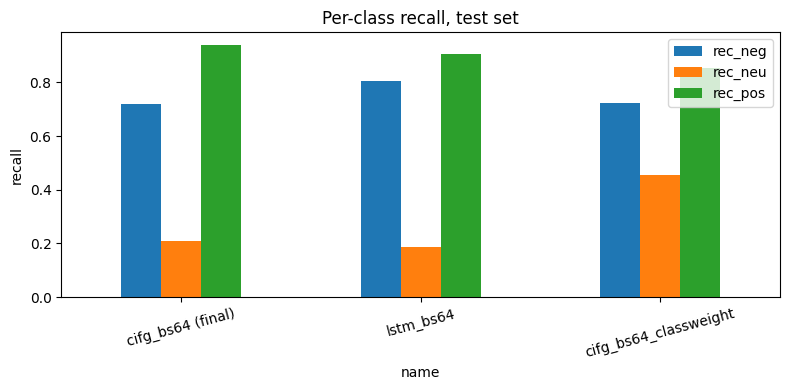

/kaggle/working/final_comparison.csv

/kaggle/working/final_comparison.png

In [16]:
from sklearn.metrics import recall_score, accuracy_score, f1_score, classification_report
from IPython.display import FileLink, display

assert "res" in globals() and "pred" in globals(), "run the final model cell first"
yt = yte.numpy()

def row(name, r, p):
    rec = recall_score(yt, p, average=None)
    return dict(name=name, params=r["params"], epochs_run=r["epochs_run"],
                test_acc=r["test_acc"], test_f1=r["test_f1"],
                rec_neg=rec[0], rec_neu=rec[1], rec_pos=rec[2])

cmp_rows = [row("cifg_bs64 (final)", res, pred)]
experiments = {
    "lstm_bs64":             dict(cell="lstm", bs=64),
    "cifg_bs64_classweight": dict(cell="cifg", bs=64, class_weight=True),
}
for name, kw in experiments.items():
    r, h, _, p = run(epochs=12, patience=4, seed=0, verbose=True, **kw)
    cmp_rows.append(row(name, r, p))
    print("-->", name, "test F1:", round(r["test_f1"], 4), "| neutral recall:", round(cmp_rows[-1]["rec_neu"], 3))
    cmp = pd.DataFrame(cmp_rows).set_index("name").round(4)
    cmp.to_csv("final_comparison.csv")                     # saved after every run

print(cmp)
ax = cmp[["rec_neg", "rec_neu", "rec_pos"]].plot.bar(figsize=(8, 4), rot=15)
ax.set_ylabel("recall"); ax.set_title("Per-class recall, test set")
plt.tight_layout(); plt.savefig("final_comparison.png", dpi=150); plt.show()
for f in ["final_comparison.csv", "final_comparison.png"]: display(FileLink(f))

In [17]:
# ---- part 1: retrain the four A models (same settings and seed as Experiment A) ----
MODELS = {}
for c in ["lstm", "wmc", "cifg", "lstmp"]:
    _, _, MODELS[c], _ = run(cell=c, seed=0, epochs=8, verbose=False, do_test=False)
    print("trained", c)

trained lstm
trained wmc
trained cifg
trained lstmp


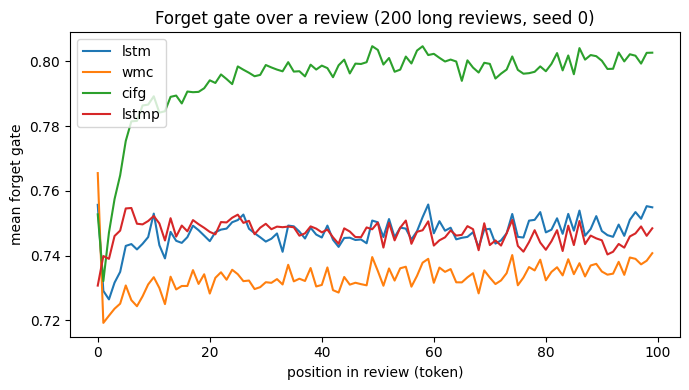

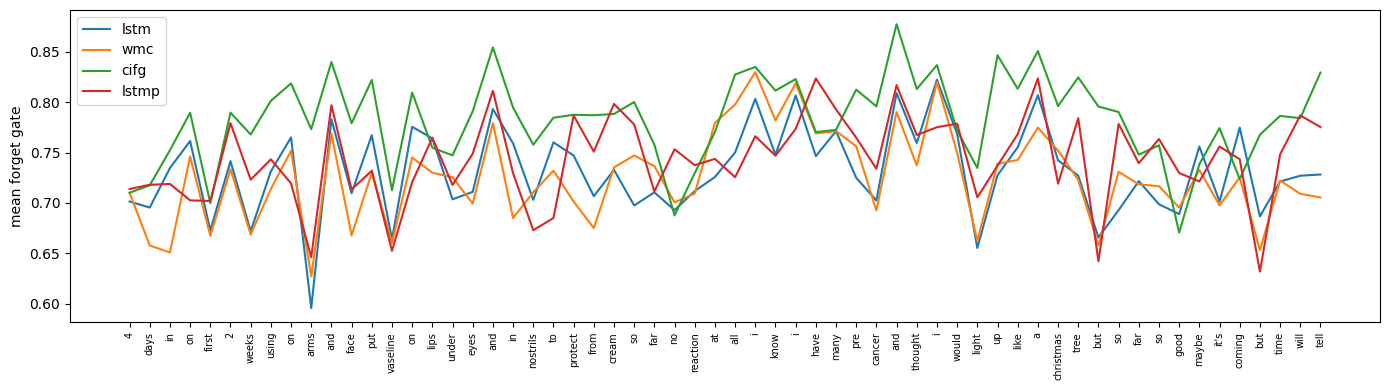

review: 4 days in on first 2 weeks using on arms and face put vaseline on lips under eyes and in nostrils to protect from cream so far no reaction at all i know i have many pre cancer and thought i would light up like a christmas tree but so far so good maybe it's coming but time will tell


/kaggle/working/gate_position.png

/kaggle/working/gate_tokens.png

In [18]:
# ---- part 2: forget-gate traces ----
@torch.no_grad()
def forget_trace(model, cell_name, x):
    """mean forget-gate value at each time step for one review x of shape (1, L)"""
    model.eval(); cell = model.enc.cells[0]; H = cell.H
    xw = cell.x2h(model.emb(x))
    h = xw.new_zeros(1, cell.h_dim); c = xw.new_zeros(1, cell.c_dim); out = []
    for t in range(xw.shape[1]):
        pre = xw[:, t] + cell.h2h(h)
        if cell_name == "cifg":                      # gate order f, g, o
            f = torch.sigmoid(pre[:, :H])
        elif cell_name == "wmc":                     # gate order i, f, g, o, plus the peephole term
            cf = torch.tanh(cell.c2if(c)).chunk(2, -1)[1]
            f = torch.sigmoid(pre[:, H:2*H] + cf)
        else:                                        # lstm and lstmp: gate order i, f, g, o
            f = torch.sigmoid(pre[:, H:2*H])
        out.append(f.mean())
        h, c = cell(xw[:, t], h, c)
    return torch.stack(out).cpu().numpy()

lens_np, y_np = Lte.numpy(), yte.numpy()

# (a) mean forget gate by position, averaged over 200 long test reviews
idx = [i for i in range(len(lens_np)) if lens_np[i] >= 100][:200]
plt.figure(figsize=(7, 4))
for c_name, m_ in MODELS.items():
    avg = np.mean([forget_trace(m_, c_name, Xte[i:i+1, :100].to(device)) for i in idx], 0)
    plt.plot(avg, label=c_name)
plt.xlabel("position in review (token)"); plt.ylabel("mean forget gate"); plt.legend()
plt.title("Forget gate over a review (200 long reviews, seed 0)")
plt.tight_layout(); plt.savefig("gate_position.png", dpi=150); plt.show()

# (b) token-level view on one negative review
j = next(i for i in range(len(lens_np)) if y_np[i] == 0 and 30 <= lens_np[i] <= 60)
L = int(lens_np[j]); toks = [itos[t] for t in Xte[j, :L].tolist()]
x = Xte[j:j+1, :L].to(device)
plt.figure(figsize=(14, 4))
for c_name, m_ in MODELS.items(): plt.plot(forget_trace(m_, c_name, x), label=c_name)
plt.xticks(range(L), toks, rotation=90, fontsize=7); plt.ylabel("mean forget gate"); plt.legend()
plt.tight_layout(); plt.savefig("gate_tokens.png", dpi=150); plt.show()
print("review:", " ".join(toks))

for f in ["gate_position.png", "gate_tokens.png"]: display(FileLink(f))

In [20]:
with torch.no_grad():
    mine.h2h.weight[0, 0] += 1e-3                     # deliberate error
h = torch.zeros(B, H).double(); c = torch.zeros(B, H).double(); outs = []
for t in range(T):
    h, c = mine(xw[:, t], h, c); outs.append(h)
print("diff after deliberate error:", (torch.stack(outs, 1) - ref_out).abs().max().item())

diff after deliberate error: 3.4426361803341354e-05


In [23]:
import torch, torch.nn.functional as F

# use the final model if it is still in memory, otherwise reload the saved weights
try:
    clf = model
except NameError:
    clf = Classifier(len(itos), "cifg", 128, 128, 64, 1, 0.3).to(device)
    clf.load_state_dict(torch.load("final_cifg.pt", map_location=device))
clf.eval()

reviews = [
  "This medication changed my life, no side effects and my pain is gone.",
  "Terrible. Nausea every day and it did nothing for my anxiety.",
  "It worked a little but the headaches were annoying, I'm not sure it is worth it.",
  "Great at first but it stopped working and the side effects got worse.",
]
names = ["negative", "neutral", "positive"]

@torch.no_grad()
def probs(text):
    ids = [stoi.get(w, 1) for w in tokenize(text)[:MAX_LEN]] or [1]
    x = torch.tensor([ids]).to(device); L = torch.tensor([len(ids)]).to(device)
    return F.softmax(clf(x, L), -1)[0].cpu().numpy()

rows = []
for t in reviews:
    p = probs(t)
    print(f"{names[p.argmax()]:9s} neg {p[0]:.2f} | neu {p[1]:.2f} | pos {p[2]:.2f}  <- {t}")
    rows.append(f"``{t}'' & {names[p.argmax()]} & {p[0]:.2f} & {p[1]:.2f} & {p[2]:.2f}\\\\")


print("\n".join(rows))

positive  neg 0.00 | neu 0.00 | pos 1.00  <- This medication changed my life, no side effects and my pain is gone.
negative  neg 1.00 | neu 0.00 | pos 0.00  <- Terrible. Nausea every day and it did nothing for my anxiety.
neutral   neg 0.34 | neu 0.49 | pos 0.18  <- It worked a little but the headaches were annoying, I'm not sure it is worth it.
negative  neg 0.49 | neu 0.25 | pos 0.27  <- Great at first but it stopped working and the side effects got worse.
``This medication changed my life, no side effects and my pain is gone.'' & positive & 0.00 & 0.00 & 1.00\\
``Terrible. Nausea every day and it did nothing for my anxiety.'' & negative & 1.00 & 0.00 & 0.00\\
``It worked a little but the headaches were annoying, I'm not sure it is worth it.'' & neutral & 0.34 & 0.49 & 0.18\\
``Great at first but it stopped working and the side effects got worse.'' & negative & 0.49 & 0.25 & 0.27\\


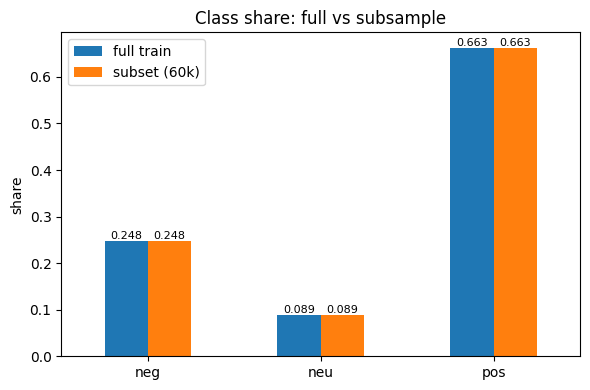

     full train  subset (60k)
neg       0.248         0.248
neu       0.089         0.089
pos       0.663         0.663


/kaggle/working/subset_check.png

In [24]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import FileLink, display

shares = pd.DataFrame({
    "full train":   train_full.label.value_counts(normalize=True).sort_index(),
    "subset (60k)": pd.Series(np.bincount(ytr.numpy()) / len(ytr)),
})
shares.index = ["neg", "neu", "pos"]

ax = shares.plot.bar(figsize=(6, 4), rot=0)
ax.set_ylabel("share"); ax.set_title("Class share: full vs subsample")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.savefig("subset_check.png", dpi=170); plt.show()

print(shares.round(3))
display(FileLink("subset_check.png"))